# Model Evaluation and Comparison

This notebook compares Logistic Regression and XGBoost
using three different feature sets.

The validation results are used to understand the performance
of each model and select the best model.

The trained models are then evaluated on the held-out test
dataset to assess their performance on unseen reports.

Average Precision is used as the main evaluation metric
because of the high class imbalance in the dataset.

In [1]:
import os
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import sparse
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_curve
)

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
data_dir = "/content/drive/MyDrive/model_processed/pilot_2014q1"

results_dir = "/content/drive/MyDrive/model_results/pilot_2014q1"

lr_dir = f"{results_dir}/logistic_regression"
xgb_dir = f"{results_dir}/xgboost"

comparison_dir = f"{results_dir}/model_comparison"

os.makedirs(comparison_dir, exist_ok=True)
os.makedirs(f"{comparison_dir}/figures", exist_ok=True)

print("Folders ready.")

Folders ready.


Load validation results

In [3]:
lr_default = pd.read_csv(
    f"{lr_dir}/metrics/default_threshold_results.csv"
)

lr_optimized = pd.read_csv(
    f"{lr_dir}/metrics/optimized_threshold_results.csv"
)

xgb_default = pd.read_csv(
    f"{xgb_dir}/metrics/default_threshold_results.csv"
)

xgb_optimized = pd.read_csv(
    f"{xgb_dir}/metrics/optimized_threshold_results.csv"
)

lr_default["Model"] = "Logistic Regression"
lr_optimized["Model"] = "Logistic Regression"

xgb_default["Model"] = "XGBoost"
xgb_optimized["Model"] = "XGBoost"

print("Validation results loaded successfully.")

Validation results loaded successfully.


Combine model results

In [4]:
default_results = pd.concat(
    [lr_default, xgb_default],
    ignore_index=True
)

optimized_results = pd.concat(
    [lr_optimized, xgb_optimized],
    ignore_index=True
)

columns = [
    "Model",
    "Experiment",
    "Threshold",
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "Average Precision"
]

print("Default threshold results")
display(default_results[columns].round(4))

print("\nOptimized threshold results")
display(optimized_results[columns].round(4))

Default threshold results


,Model,Experiment,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,E1_Basic,0.5,0.7729,0.7065,0.0580,0.6370,0.1063,0.7747,0.1408
1,Logistic Regression,E2_Extended,0.5,0.7806,0.7134,0.0605,0.6433,0.1106,0.7881,0.1627
2,Logistic Regression,E3_Contextual,0.5,0.7911,0.7218,0.0640,0.6496,0.1165,0.7971,0.1491
3,XGBoost,E1_Basic,0.5,0.7289,0.6803,0.0482,0.6295,0.0896,0.7579,0.1194
4,XGBoost,E2_Extended,0.5,0.7870,0.7032,0.0599,0.6158,0.1092,0.7821,0.1672
5,XGBoost,E3_Contextual,0.5,0.7938,0.7043,0.0614,0.6108,0.1116,0.7880,0.2033



Optimized threshold results


,Model,Experiment,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,E1_Basic,0.8456,0.9603,0.6210,0.1898,0.2666,0.2218,0.7747,0.1408
1,Logistic Regression,E2_Extended,0.8556,0.9632,0.6261,0.2135,0.2741,0.2400,0.7881,0.1627
2,Logistic Regression,E3_Contextual,0.8767,0.9649,0.6227,0.2241,0.2653,0.2430,0.7971,0.1491
3,XGBoost,E1_Basic,0.7280,0.9656,0.6059,0.2130,0.2303,0.2213,0.7579,0.1194
4,XGBoost,E2_Extended,0.7705,0.9679,0.6273,0.2568,0.2716,0.2640,0.7821,0.1672
5,XGBoost,E3_Contextual,0.7938,0.9719,0.6208,0.3048,0.2541,0.2771,0.7880,0.2033


In [5]:
ranked_models = optimized_results.sort_values(
    "Average Precision",
    ascending=False
).reset_index(drop=True)

ranked_models.insert(
    0, "Rank", range(1, len(ranked_models) + 1)
)

display(ranked_models[["Rank"] + columns].round(4))

,Rank,Model,Experiment,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,1,XGBoost,E3_Contextual,0.7938,0.9719,0.6208,0.3048,0.2541,0.2771,0.7880,0.2033
1,2,XGBoost,E2_Extended,0.7705,0.9679,0.6273,0.2568,0.2716,0.2640,0.7821,0.1672
2,3,Logistic Regression,E2_Extended,0.8556,0.9632,0.6261,0.2135,0.2741,0.2400,0.7881,0.1627
3,4,Logistic Regression,E3_Contextual,0.8767,0.9649,0.6227,0.2241,0.2653,0.2430,0.7971,0.1491
4,5,Logistic Regression,E1_Basic,0.8456,0.9603,0.6210,0.1898,0.2666,0.2218,0.7747,0.1408
5,6,XGBoost,E1_Basic,0.7280,0.9656,0.6059,0.2130,0.2303,0.2213,0.7579,0.1194


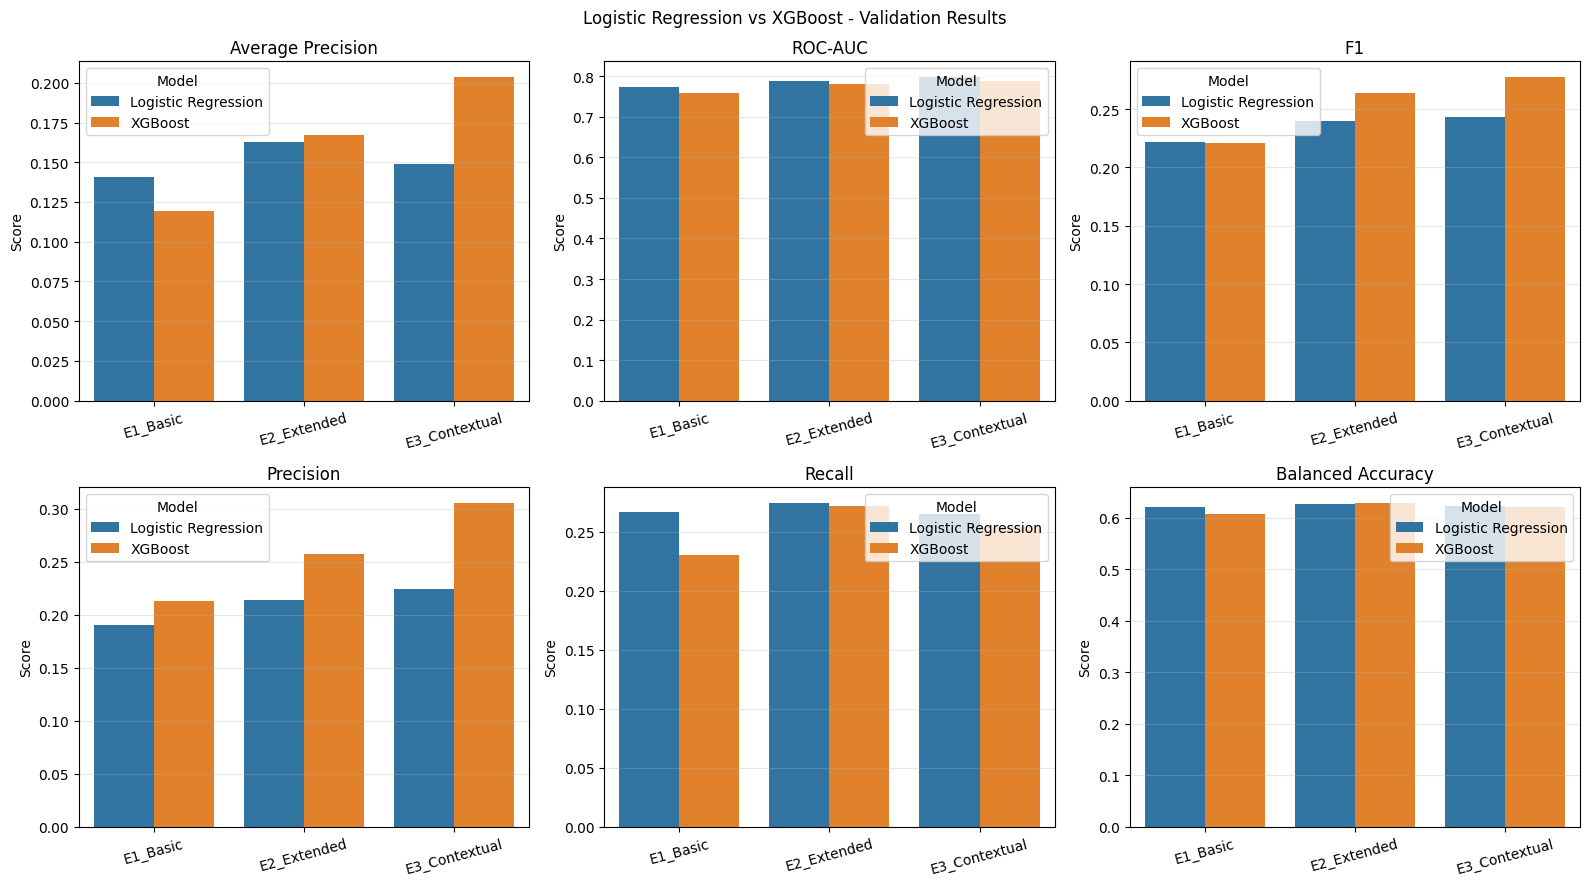

In [6]:
metrics = [
    "Average Precision",
    "ROC-AUC",
    "F1",
    "Precision",
    "Recall",
    "Balanced Accuracy"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, metric in zip(axes.flatten(), metrics):

    sns.barplot(
        data=optimized_results,
        x="Experiment",
        y=metric,
        hue="Model",
        ax=ax
    )

    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Logistic Regression vs XGBoost - Validation Results")
plt.tight_layout()

plt.savefig(
    f"{comparison_dir}/figures/validation_comparison.png",
    dpi=300
)

plt.show()

Compare Average Precision improvements

In [7]:
ap_comparison = optimized_results.pivot(
    index="Experiment",
    columns="Model",
    values="Average Precision"
).reset_index()

ap_comparison["Difference"] = (
    ap_comparison["XGBoost"]
    - ap_comparison["Logistic Regression"]
)

ap_comparison["Improvement (%)"] = (
    ap_comparison["Difference"]
    / ap_comparison["Logistic Regression"]
) * 100

display(ap_comparison.round(4))

Model,Experiment,Logistic Regression,XGBoost,Difference,Improvement (%)
0,E1_Basic,0.1408,0.1194,-0.0215,-15.2566
1,E2_Extended,0.1627,0.1672,0.0045,2.7920
2,E3_Contextual,0.1491,0.2033,0.0542,36.3558


Compare the best model from each approach

In [8]:
best_lr = lr_optimized.sort_values(
    "Average Precision",
    ascending=False
).head(1)

best_xgb = xgb_optimized.sort_values(
    "Average Precision",
    ascending=False
).head(1)

best_models = pd.concat(
    [best_lr, best_xgb],
    ignore_index=True
)

display(best_models[columns].round(4))

,Model,Experiment,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,E2_Extended,0.8556,0.9632,0.6261,0.2135,0.2741,0.2400,0.7881,0.1627
1,XGBoost,E3_Contextual,0.7938,0.9719,0.6208,0.3048,0.2541,0.2771,0.7880,0.2033


**Validation Results and Model Comparison**

Logistic Regression and XGBoost were compared using the same three feature sets and validation dataset.

Logistic Regression performed better when only basic features were used. However, XGBoost showed greater improvement as drug administration and contextual information were added.

The contextual XGBoost model (E3) achieved the highest Average Precision of 0.2033, which is approximately 25% higher than the best Logistic Regression result. It also achieved the highest optimized F1-score of 0.2771 and precision of 0.3048.

Although Logistic Regression achieved higher ROC-AUC values, XGBoost performed better in terms of Average Precision when extended and contextual features were included.

These results suggest that XGBoost may be better at learning relationships between the additional features. However, the relatively low recall shows that identifying hypersensitivity-related reports remains challenging.

Based on Average Precision, XGBoost with the contextual feature set (E3) was selected as the preferred model for the pilot study.

Model selection and test evaluation

In [9]:
selected_model = ranked_models.iloc[0]

selected_model_name = selected_model["Model"]
selected_experiment = selected_model["Experiment"]
selected_threshold = float(selected_model["Threshold"])

print("Selected model:", selected_model_name)
print("Feature set:", selected_experiment)
print("Classification threshold:", selected_threshold)

print(
    "Validation Average Precision:",
    round(selected_model["Average Precision"], 4)
)

print(
    "Validation F1-score:",
    round(selected_model["F1"], 4)
)

Selected model: XGBoost
Feature set: E3_Contextual
Classification threshold: 0.7937632
Validation Average Precision: 0.2033
Validation F1-score: 0.2771


In [10]:
model_selection = {
    "selected_model": selected_model_name,
    "selected_experiment": selected_experiment,
    "selection_metric": "Average Precision",
    "selection_dataset": "Validation",
    "classification_threshold": selected_threshold,
    "threshold_selection_metric": "F1",
    "validation_average_precision": float(
        selected_model["Average Precision"]
    ),
    "validation_f1": float(selected_model["F1"]),
    "test_evaluated_at_selection": False
}

with open(f"{comparison_dir}/model_selection.json", "w") as file:
    json.dump(model_selection, file, indent=4)

print("Model selection saved.")

Model selection saved.


In [11]:
with open(f"{data_dir}/metadata.json", "r") as file:
    metadata = json.load(file)

experiments = metadata["experiments"]

y_test = np.load(f"{data_dir}/targets/y_test.npy")

test_data = {}

for name in experiments:

    X_test = sparse.load_npz(
        f"{data_dir}/{name}/X_test.npz"
    )

    assert X_test.shape[0] == len(y_test)

    test_data[name] = X_test

    print(name, X_test.shape)

print("\nTotal test reports:", len(y_test))
print("Negative reports:", (y_test == 0).sum())
print("Positive reports:", (y_test == 1).sum())

E1_Basic (37687, 677)
E2_Extended (37687, 1004)
E3_Contextual (37687, 1664)

Total test reports: 37687
Negative reports: 36888
Positive reports: 799


Load trained models and thresholds

In [12]:
lr_models = {}
xgb_models = {}

with open(f"{lr_dir}/optimal_thresholds.json", "r") as file:
    lr_thresholds = json.load(file)

with open(f"{xgb_dir}/optimal_thresholds.json", "r") as file:
    xgb_thresholds = json.load(file)

for name in experiments:

    lr_models[name] = joblib.load(
        f"{lr_dir}/models/{name}_logistic_regression.joblib"
    )

    model = XGBClassifier()

    model.load_model(
        f"{xgb_dir}/models/{name}_xgboost.json"
    )

    xgb_models[name] = model

    print(f"{name}: Both models loaded.")

print("\nAll trained models loaded successfully.")

E1_Basic: Both models loaded.
E2_Extended: Both models loaded.
E3_Contextual: Both models loaded.

All trained models loaded successfully.


In [13]:
def evaluate_model(y_true, probabilities, threshold=0.5):

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Average Precision": average_precision_score(y_true, probabilities),
        "Specificity": tn / (tn + fp),
        "True Negatives": int(tn),
        "False Positives": int(fp),
        "False Negatives": int(fn),
        "True Positives": int(tp)
    }

Evaluate the dummy classifier

In [14]:
dummy_probabilities = np.zeros(len(y_test))

dummy_test_results = evaluate_model(
    y_test,
    dummy_probabilities
)

dummy_test_df = pd.DataFrame([dummy_test_results])

display(dummy_test_df.round(4))

,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Specificity,True Negatives,False Positives,False Negatives,True Positives
0,0.5,0.9788,0.5,0.0,0.0,0.0,0.5,0.0212,1.0,36888,0,799,0


In [15]:
test_default_results = []
test_optimized_results = []
test_probabilities = {}

model_groups = [
    ("Logistic Regression", lr_models, lr_thresholds),
    ("XGBoost", xgb_models, xgb_thresholds)
]

for model_name, models, thresholds in model_groups:

    for name in experiments:

        model = models[name]
        X_test = test_data[name]

        probabilities = model.predict_proba(X_test)[:, 1]

        test_probabilities[(model_name, name)] = probabilities

        # Evaluate using the default threshold
        default_metrics = evaluate_model(
            y_test, probabilities, 0.5
        )

        default_metrics["Model"] = model_name
        default_metrics["Experiment"] = name

        test_default_results.append(default_metrics)

        # Evaluate using the saved validation threshold
        optimized_metrics = evaluate_model(
            y_test, probabilities, thresholds[name]
        )

        optimized_metrics["Model"] = model_name
        optimized_metrics["Experiment"] = name

        test_optimized_results.append(optimized_metrics)

        print(f"{model_name} - {name}: Evaluation completed.")

print("\nAll test evaluations completed.")

Logistic Regression - E1_Basic: Evaluation completed.
Logistic Regression - E2_Extended: Evaluation completed.
Logistic Regression - E3_Contextual: Evaluation completed.
XGBoost - E1_Basic: Evaluation completed.
XGBoost - E2_Extended: Evaluation completed.
XGBoost - E3_Contextual: Evaluation completed.

All test evaluations completed.


In [16]:
test_default_df = pd.DataFrame(test_default_results)

test_optimized_df = pd.DataFrame(test_optimized_results)

print("Test results - Default threshold")

display(test_default_df[columns].round(4))

print("\nTest results - Optimized threshold")

display(test_optimized_df[columns].round(4))

Test results - Default threshold


,Model,Experiment,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,E1_Basic,0.5,0.7793,0.7042,0.0587,0.6258,0.1073,0.7710,0.1399
1,Logistic Regression,E2_Extended,0.5,0.7859,0.7119,0.0612,0.6345,0.1117,0.7823,0.1519
2,Logistic Regression,E3_Contextual,0.5,0.7995,0.7194,0.0654,0.6358,0.1185,0.7831,0.1533
3,XGBoost,E1_Basic,0.5,0.7318,0.6903,0.0500,0.6471,0.0928,0.7600,0.1312
4,XGBoost,E2_Extended,0.5,0.7944,0.7174,0.0639,0.6370,0.1161,0.7896,0.1799
5,XGBoost,E3_Contextual,0.5,0.8009,0.7177,0.0653,0.6308,0.1184,0.7960,0.2104



Test results - Optimized threshold


,Model,Experiment,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,E1_Basic,0.8456,0.9607,0.6151,0.1868,0.2541,0.2153,0.7710,0.1399
1,Logistic Regression,E2_Extended,0.8556,0.9650,0.6270,0.2284,0.2741,0.2491,0.7823,0.1519
2,Logistic Regression,E3_Contextual,0.8767,0.9677,0.6217,0.2494,0.2603,0.2547,0.7831,0.1533
3,XGBoost,E1_Basic,0.7280,0.9659,0.6006,0.2093,0.2190,0.2141,0.7600,0.1312
4,XGBoost,E2_Extended,0.7705,0.9695,0.6262,0.2744,0.2678,0.2711,0.7896,0.1799
5,XGBoost,E3_Contextual,0.7938,0.9739,0.6181,0.3397,0.2466,0.2857,0.7960,0.2104


Compare validation and test performance

In [17]:
comparison_metrics = [
    "Model",
    "Experiment",
    "Average Precision",
    "ROC-AUC",
    "Precision",
    "Recall",
    "F1"
]

validation_test_comparison = optimized_results[
    comparison_metrics
].merge(
    test_optimized_df[comparison_metrics],
    on=["Model", "Experiment"],
    suffixes=("_Validation", "_Test")
)

validation_test_comparison["AP Difference"] = (
    validation_test_comparison["Average Precision_Test"]
    - validation_test_comparison["Average Precision_Validation"]
)

validation_test_comparison["F1 Difference"] = (
    validation_test_comparison["F1_Test"]
    - validation_test_comparison["F1_Validation"]
)

display(validation_test_comparison.round(4))

,Model,Experiment,Average Precision_Validation,ROC-AUC_Validation,Precision_Validation,Recall_Validation,F1_Validation,Average Precision_Test,ROC-AUC_Test,Precision_Test,Recall_Test,F1_Test,AP Difference,F1 Difference
0,Logistic Regression,E1_Basic,0.1408,0.7747,0.1898,0.2666,0.2218,0.1399,0.7710,0.1868,0.2541,0.2153,-0.0009,-0.0065
1,Logistic Regression,E2_Extended,0.1627,0.7881,0.2135,0.2741,0.2400,0.1519,0.7823,0.2284,0.2741,0.2491,-0.0107,0.0091
2,Logistic Regression,E3_Contextual,0.1491,0.7971,0.2241,0.2653,0.2430,0.1533,0.7831,0.2494,0.2603,0.2547,0.0042,0.0118
3,XGBoost,E1_Basic,0.1194,0.7579,0.2130,0.2303,0.2213,0.1312,0.7600,0.2093,0.2190,0.2141,0.0118,-0.0072
4,XGBoost,E2_Extended,0.1672,0.7821,0.2568,0.2716,0.2640,0.1799,0.7896,0.2744,0.2678,0.2711,0.0127,0.0071
5,XGBoost,E3_Contextual,0.2033,0.7880,0.3048,0.2541,0.2771,0.2104,0.7960,0.3397,0.2466,0.2857,0.0070,0.0086


Visualize validation and test performance

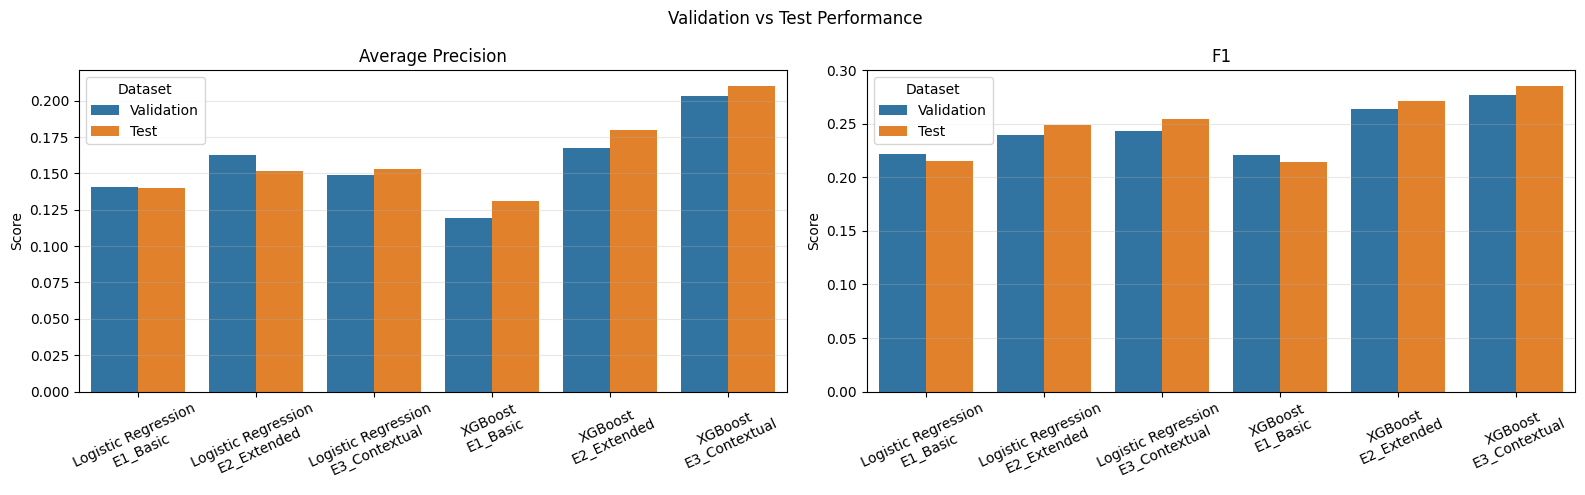

In [18]:
plot_data = pd.concat([
    optimized_results.assign(Dataset="Validation"),
    test_optimized_df.assign(Dataset="Test")
], ignore_index=True)

plot_data["Model and Experiment"] = (
    plot_data["Model"] + "\n" + plot_data["Experiment"]
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, metric in zip(axes, ["Average Precision", "F1"]):

    sns.barplot(
        data=plot_data,
        x="Model and Experiment",
        y=metric,
        hue="Dataset",
        ax=ax
    )

    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Validation vs Test Performance")
plt.tight_layout()

plt.savefig(
    f"{comparison_dir}/figures/validation_vs_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
selected_test_results = test_optimized_df[
    (test_optimized_df["Model"] == selected_model_name) &
    (test_optimized_df["Experiment"] == selected_experiment)
]

display(selected_test_results.T)

,5
Threshold,0.793763
Accuracy,0.973864
Balanced Accuracy,0.618088
Precision,0.339655
Recall,0.246558
F1,0.285714
ROC-AUC,0.796046
Average Precision,0.210363
Specificity,0.989617
True Negatives,36505


Confusion matrix of the selected model

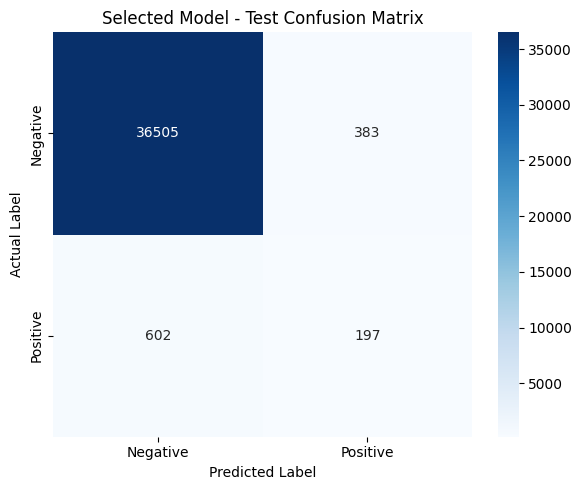

In [20]:
selected_probabilities = test_probabilities[
    (selected_model_name, selected_experiment)
]

selected_predictions = (
    selected_probabilities >= selected_threshold
).astype(int)

cm = confusion_matrix(
    y_test, selected_predictions, labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Selected Model - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    f"{comparison_dir}/figures/selected_model_confusion_matrix.png",
    dpi=300
)

plt.show()

ROC curves for all models

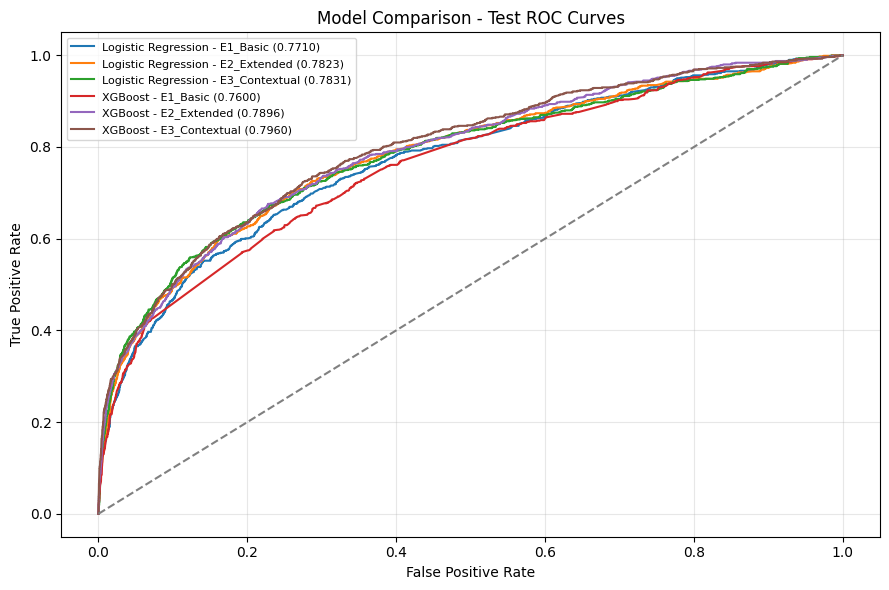

In [21]:
plt.figure(figsize=(9, 6))

for (model_name, name), probabilities in test_probabilities.items():

    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr, tpr,
        label=f"{model_name} - {name} ({auc:.4f})"
    )

plt.plot([0, 1], [0, 1], "--", color="gray")

plt.title("Model Comparison - Test ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{comparison_dir}/figures/test_roc_curves.png",
    dpi=300
)

plt.show()

Precision-Recall curves for all models

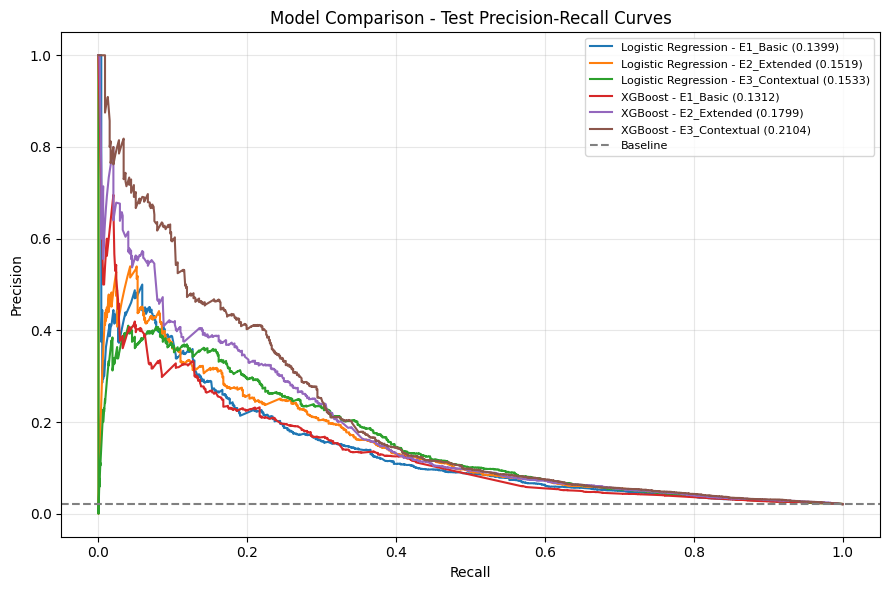

In [22]:
plt.figure(figsize=(9, 6))

for (model_name, name), probabilities in test_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_test, probabilities
    )

    ap = average_precision_score(y_test, probabilities)

    plt.plot(
        recall, precision,
        label=f"{model_name} - {name} ({ap:.4f})"
    )

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    color="gray",
    label="Baseline"
)

plt.title("Model Comparison - Test Precision-Recall Curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{comparison_dir}/figures/test_pr_curves.png",
    dpi=300
)

plt.show()

In [23]:
selected_default = test_default_df[
    (test_default_df["Model"] == selected_model_name) &
    (test_default_df["Experiment"] == selected_experiment)
]

threshold_results = pd.concat([
    selected_default.assign(Type="Default"),
    selected_test_results.assign(Type="Optimized")
])

display(
    threshold_results[
        ["Type", "Threshold", "Precision", "Recall", "F1"]
    ].round(4)
)

,Type,Threshold,Precision,Recall,F1
5,Default,0.5000,0.0653,0.6308,0.1184
5,Optimized,0.7938,0.3397,0.2466,0.2857


In [24]:
results_to_save = {
    "validation_default_results.csv": default_results,
    "validation_optimized_results.csv": optimized_results,
    "validation_model_ranking.csv": ranked_models,
    "validation_ap_comparison.csv": ap_comparison,
    "dummy_test_results.csv": dummy_test_df,
    "test_default_results.csv": test_default_df,
    "test_optimized_results.csv": test_optimized_df,
    "validation_test_comparison.csv": validation_test_comparison,
    "selected_model_test_results.csv": selected_test_results
}

for filename, dataframe in results_to_save.items():

    dataframe.to_csv(
        f"{comparison_dir}/{filename}",
        index=False
    )

    print(f"Saved: {filename}")

Saved: validation_default_results.csv
Saved: validation_optimized_results.csv
Saved: validation_model_ranking.csv
Saved: validation_ap_comparison.csv
Saved: dummy_test_results.csv
Saved: test_default_results.csv
Saved: test_optimized_results.csv
Saved: validation_test_comparison.csv
Saved: selected_model_test_results.csv


In [25]:
predictions_dir = f"{comparison_dir}/predictions"

os.makedirs(predictions_dir, exist_ok=True)

for (model_name, name), probabilities in test_probabilities.items():

    model_label = model_name.lower().replace(" ", "_")

    np.save(
        f"{predictions_dir}/{model_label}_{name}_test_probabilities.npy",
        probabilities
    )

    print(f"{model_name} - {name}: Predictions saved.")

np.save(
    f"{predictions_dir}/selected_model_test_predictions.npy",
    selected_predictions
)

np.save(
    f"{predictions_dir}/y_test.npy",
    y_test
)

Logistic Regression - E1_Basic: Predictions saved.
Logistic Regression - E2_Extended: Predictions saved.
Logistic Regression - E3_Contextual: Predictions saved.
XGBoost - E1_Basic: Predictions saved.
XGBoost - E2_Extended: Predictions saved.
XGBoost - E3_Contextual: Predictions saved.


In [26]:
evaluation_summary = {
    "dataset": metadata["dataset"],
    "selected_model": selected_model_name,
    "selected_experiment": selected_experiment,
    "classification_threshold": selected_threshold,
    "selection_metric": "Average Precision",
    "selection_dataset": "Validation",
    "evaluation_dataset": "Test",
    "test_samples": int(len(y_test)),
    "test_evaluation_completed": True,
    "test_metrics": evaluate_model(
        y_test,
        selected_probabilities,
        selected_threshold
    )
}

with open(
    f"{comparison_dir}/final_evaluation_summary.json", "w"
) as file:

    json.dump(evaluation_summary, file, indent=4)

print("Final evaluation summary saved.")

Final evaluation summary saved.


In [28]:
for filename, dataframe in results_to_save.items():

    saved_df = pd.read_csv(
        f"{comparison_dir}/{filename}"
    )

    # Reset columns.name to None to avoid index name mismatch assertions
    expected_df = dataframe.reset_index(drop=True)
    expected_df.columns.name = None
    saved_df.columns.name = None

    pd.testing.assert_frame_equal(
        saved_df,
        expected_df,
        check_dtype=False
    )

    print(f"Verified: {filename}")

for (model_name, name), probabilities in test_probabilities.items():

    model_label = model_name.lower().replace(" ", "_")

    saved_probabilities = np.load(
        f"{predictions_dir}/{model_label}_{name}_test_probabilities.npy"
    )

    assert np.array_equal(saved_probabilities, probabilities)

print("\nAll evaluation results and probabilities verified.")
print("Model evaluation and comparison completed successfully.")

Verified: validation_default_results.csv
Verified: validation_optimized_results.csv
Verified: validation_model_ranking.csv
Verified: validation_ap_comparison.csv
Verified: dummy_test_results.csv
Verified: test_default_results.csv
Verified: test_optimized_results.csv
Verified: validation_test_comparison.csv
Verified: selected_model_test_results.csv

All evaluation results and probabilities verified.
Model evaluation and comparison completed successfully.


### Model Evaluation and Comparison – Primary Findings

Logistic Regression and XGBoost were compared using three different feature sets. Average Precision was used as the main evaluation metric because hypersensitivity-related reports represent only around 2.12% of the dataset.

Based on the validation results, XGBoost with the contextual feature set (E3) was selected as the best-performing model. All six models were then evaluated on the test dataset without changing their parameters or classification thresholds.

The selected XGBoost model achieved an Average Precision of 0.2104, a ROC-AUC of 0.7960 and an F1-score of 0.2857 on the test dataset. Compared to the selected Logistic Regression baseline, Average Precision improved by approximately 38.5%.

The validation and test results were reasonably similar, suggesting that the models perform consistently on unseen reports within the pilot dataset.

Threshold optimization improved precision and F1-score but reduced recall. Although the selected model produced fewer false positive predictions, it still missed a considerable number of hypersensitivity-related reports.

The results also suggest that XGBoost benefits more from additional contextual information than Logistic Regression. However, further investigation is needed to understand whether these improvements are influenced by reporting patterns or missing information.

These findings are limited to the single-quarter pilot dataset and provisional hypersensitivity labels. Further evaluation using additional reporting periods is needed to assess generalizability. The model classifies recorded hypersensitivity-related reports rather than predicting an individual's clinical risk of developing a drug allergy.